# Play dice with more than one agent

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

import altair as alt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

from dice.agents import Agent, SmartAgent, StopAtNDiceAgent
from dice.game import FillOrBustEnvironment, determine_available_actions

In [3]:
alt.renderers.set_embed_options(theme="dark")

RendererRegistry.enable('default')

# Utility functions

In [4]:
def plot_training_metric(
    agent: Agent,
    metric: str = "num_turns_to_win",
    downsample: bool = True,
) -> None:
    # Format the data
    data = getattr(agent, metric)
    if downsample:
        data = data[:: len(data) // min(2500, len(data))]
    source = (
        pd.DataFrame(data, columns=[metric])
        .reset_index()
        .rename(columns={"index": "episode"})
    )
    print(f"Median `{metric}` after training: {source.tail(50)[metric].median()}")

    # Create the chart
    padding = int(0.1 * len(source))
    line = (
        alt.Chart(source)
        .mark_line(color="red", size=3)
        .transform_window(
            rolling_mean=f"median({metric})",
            frame=[-padding, padding],
        )
        .encode(x="episode", y="rolling_mean:Q")
    )
    points = (
        alt.Chart(source)
        .mark_point(opacity=0.2, color="orange")
        .encode(x="episode", y=alt.Y(f"{metric}:Q").title(metric))
    )

    chart = (points + line).properties(width=400, height=250)
    chart.show()

# Train an agent

In [5]:
n_episodes = 5000
start_learning_rate = 0.0001
lr_decay = start_learning_rate / (n_episodes // 2)
final_lr = 0.0001
start_epsilon = 1.0
epsilon_decay = start_epsilon / (n_episodes // 2)
final_epsilon = 0.1
discount_factor = 0.7

kwargs = dict(
    initial_learning_rate=start_learning_rate,
    learning_rate_decay=lr_decay,
    final_learning_rate=final_lr,
    initial_epsilon=start_epsilon,
    epsilon_decay=epsilon_decay,
    final_epsilon=final_epsilon,
    discount_factor=discount_factor,
)

In [35]:
agent1 = SmartAgent("agent1", **kwargs)
# agent2 = SmartAgent("agent2", **kwargs)

# agent1 = Agent("agent1")
agent2 = Agent("agent2")
agent3 = Agent("agent3")

agents = [agent1, agent2]

env = FillOrBustEnvironment()
for episode in tqdm(range(n_episodes)):
    obs, _ = env.reset_for_new_game()
    done, turn_is_over = False, False

    # play one episode
    while not done:
        for agent in agents:
            while not turn_is_over:
                action = agent.get_action(obs)
                next_obs, reward, terminated, truncated, turn_is_over, info = env.step(
                    action
                )

                agent.update(obs, action, reward, terminated, turn_is_over, next_obs, info)

                done = terminated or truncated
                obs = next_obs
            turn_is_over = False
            if done:
                break

    # if agent.name == "agent1":
    #     agent1.wins += 1
    # else:
    #     agent2.wins += 1

    for agent in agents:
        if isinstance(agent, SmartAgent):
            agent.decay_epsilon()
            agent.decay_learning_rate()

100%|██████████| 5000/5000 [00:09<00:00, 518.92it/s]


<Axes: >

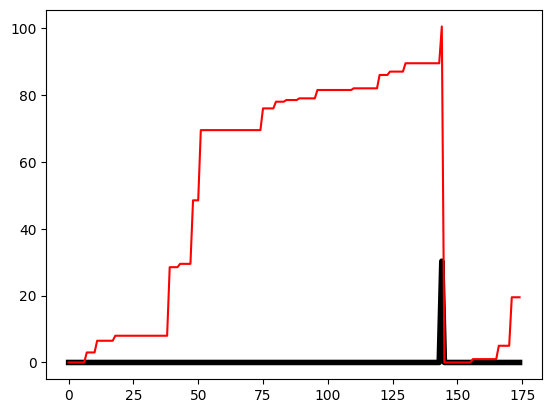

In [46]:
pd.Series(agent1.rewards).head(175).plot(style="k", lw=4)
(pd.Series(agent1.game_scores).head(175) / 1e2).plot(style="r")

<Axes: >

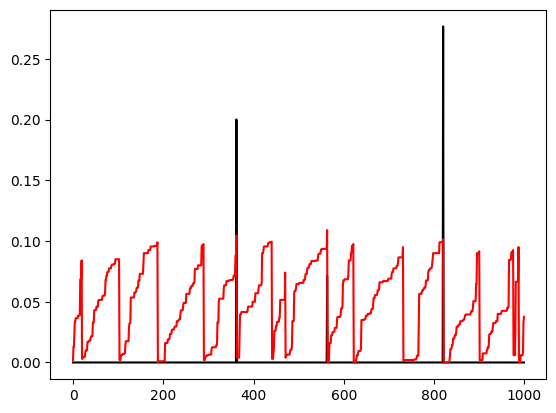

In [28]:
pd.Series(agent2.rewards).head(1000).plot(style="k")
(pd.Series(agent2.game_scores).head(1000) / 1e5).plot(style="r")

<Axes: >

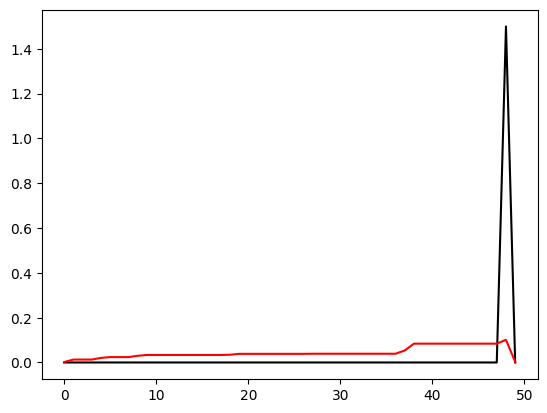

In [31]:
pd.Series(agent3.rewards).head(50).plot(style="k")
(pd.Series(agent3.game_scores).head(50) / 1e5).plot(style="r")

<Axes: >

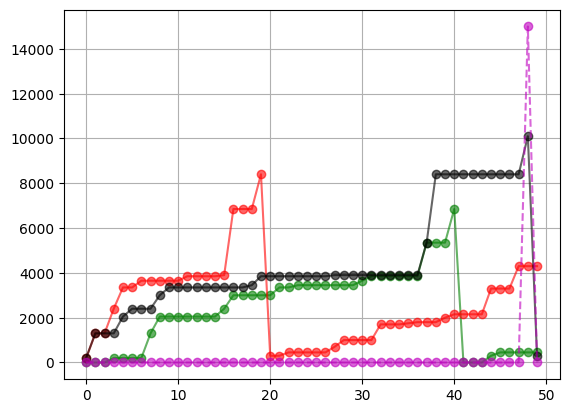

In [34]:
pd.Series(agent1.game_scores[:50]).plot(style="go-", grid=True, alpha=0.6)
pd.Series(agent2.game_scores[:50]).plot(style="ro-", grid=True, alpha=0.6)
pd.Series(agent3.game_scores[:50]).plot(style="ko-", grid=True, alpha=0.6)
(pd.Series(agent3.rewards[:50]) * 10000).plot(style="mo--", grid=True, alpha=0.6)

<Axes: >

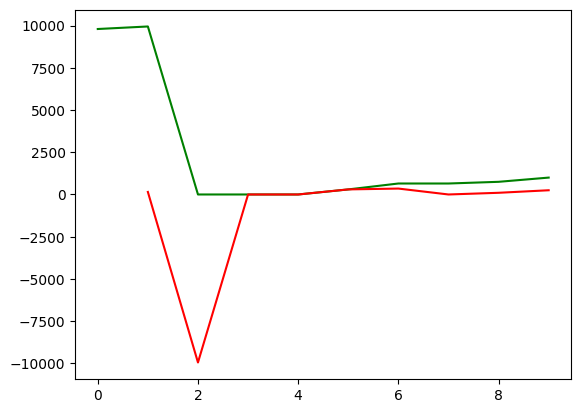

In [37]:
pd.Series(agent1.game_scores[75:85]).plot(style="g-")
pd.Series(agent1.game_scores[75:85]).diff().plot(style="r-")

<Axes: >

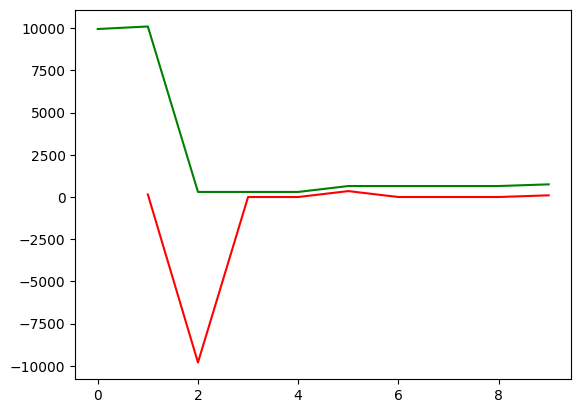

In [38]:
pd.Series(agent2.game_scores[75:85]).plot(style="g-")
pd.Series(agent2.game_scores[75:85]).diff().plot(style="r-")

<Axes: >

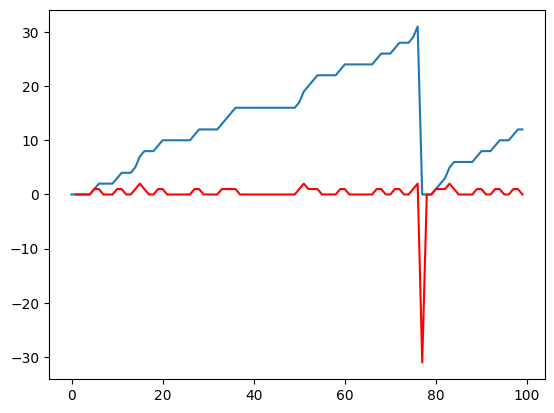

In [33]:
pd.Series(agent1.num_turns[:100]).plot()
pd.Series(agent1.num_turns[:100]).diff().plot(style="r-")

<Axes: >

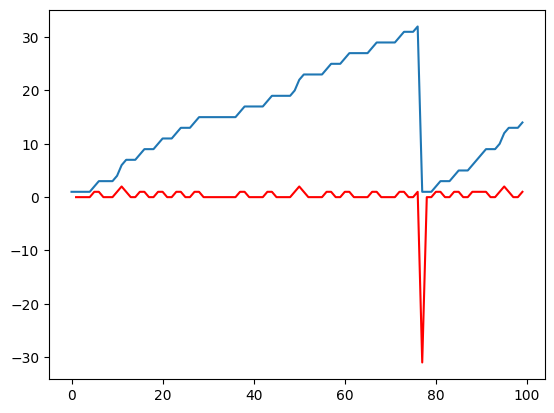

In [34]:
pd.Series(agent2.num_turns[:100]).plot()
pd.Series(agent2.num_turns[:100]).diff().plot(style="r-")

In [7]:
print(f"Agent 1 wins: {agent1.wins}")
print(f"Agent 2 wins: {agent2.wins}")

Agent 1 wins: 2427
Agent 2 wins: 2573


<Axes: >

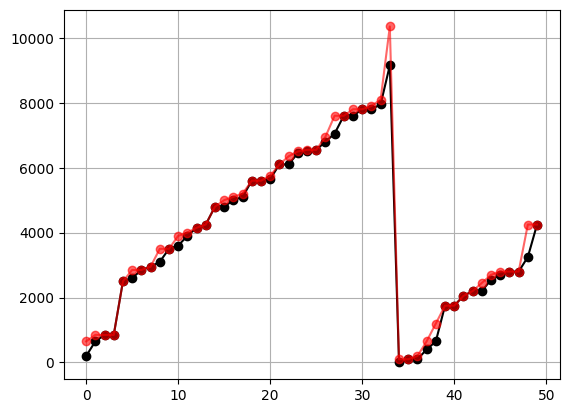

In [35]:
pd.Series(agent1.game_scores).head(50).plot(style="ko-", grid=True)
pd.Series(agent2.game_scores).head(50).plot(style="ro-", grid=True, alpha=0.6)

In [36]:
len(agent1.game_scores)

218925

In [37]:
len(agent2.game_scores)

214003

In [ ]:
num_game = 0
num_turns_in_game = agent1.num_turns[num_game]
pd.Series(agent1.game_scores[0:num_turns_in_game]).plot(style="ko-")

num_turns_in_game = agent2.num_turns[num_game]
pd.Series(agent2.game_scores[0:num_turns_in_game]).plot(style="r--", lw=2)

In [ ]:
def sort_q_values(q):
    return {
        (
            obs.hold_score,
            obs.num_dice_remaining,
            f"{obs.card.category}_{obs.card.bonus}" if obs.card else "",
        ): {
            key[1]: q[obs][key]
            for key in sorted(q[obs].keys(), key=q[obs].get, reverse=True)
        }
        for obs in sorted(
            q.keys(),
            key=lambda o: sum(q[o].values()),
            # key=lambda o: o.hold_score,
            reverse=True,
        )
        # if any(action[0] == "inherit" for action in q[obs].keys())
    }

In [ ]:
q = sort_q_values(agent1.q_values)

In [ ]:
q